<a href="https://colab.research.google.com/github/Tejasp9090/ML_Practice/blob/main/Titanic_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

In [2]:
path =  'https://raw.githubusercontent.com/datasciencedojo/datasets/refs/heads/master/titanic.csv'

t = pd.read_csv(path)
t.head(2)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C


In [3]:
t.shape

(891, 12)

In [4]:
# Missing Values
t.isna().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [5]:
t.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [6]:
# 1. Fill missing Age values with the median
t['Age'] = t['Age'].fillna(t['Age'].median())

# 2. Fill missing Embarked values with the mode
t['Embarked'] = t['Embarked'].fillna(t['Embarked'].mode()[0])

# 3. Drop Cabin because it has many missing values
t = t.drop(columns=['Cabin'])

In [7]:
print(t.isna().sum())

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


In [8]:
t.Survived.values

array([0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1,
       1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1,
       1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1,
       1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0,
       0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0,
       1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0,
       1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0,
       0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0,
       1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1,

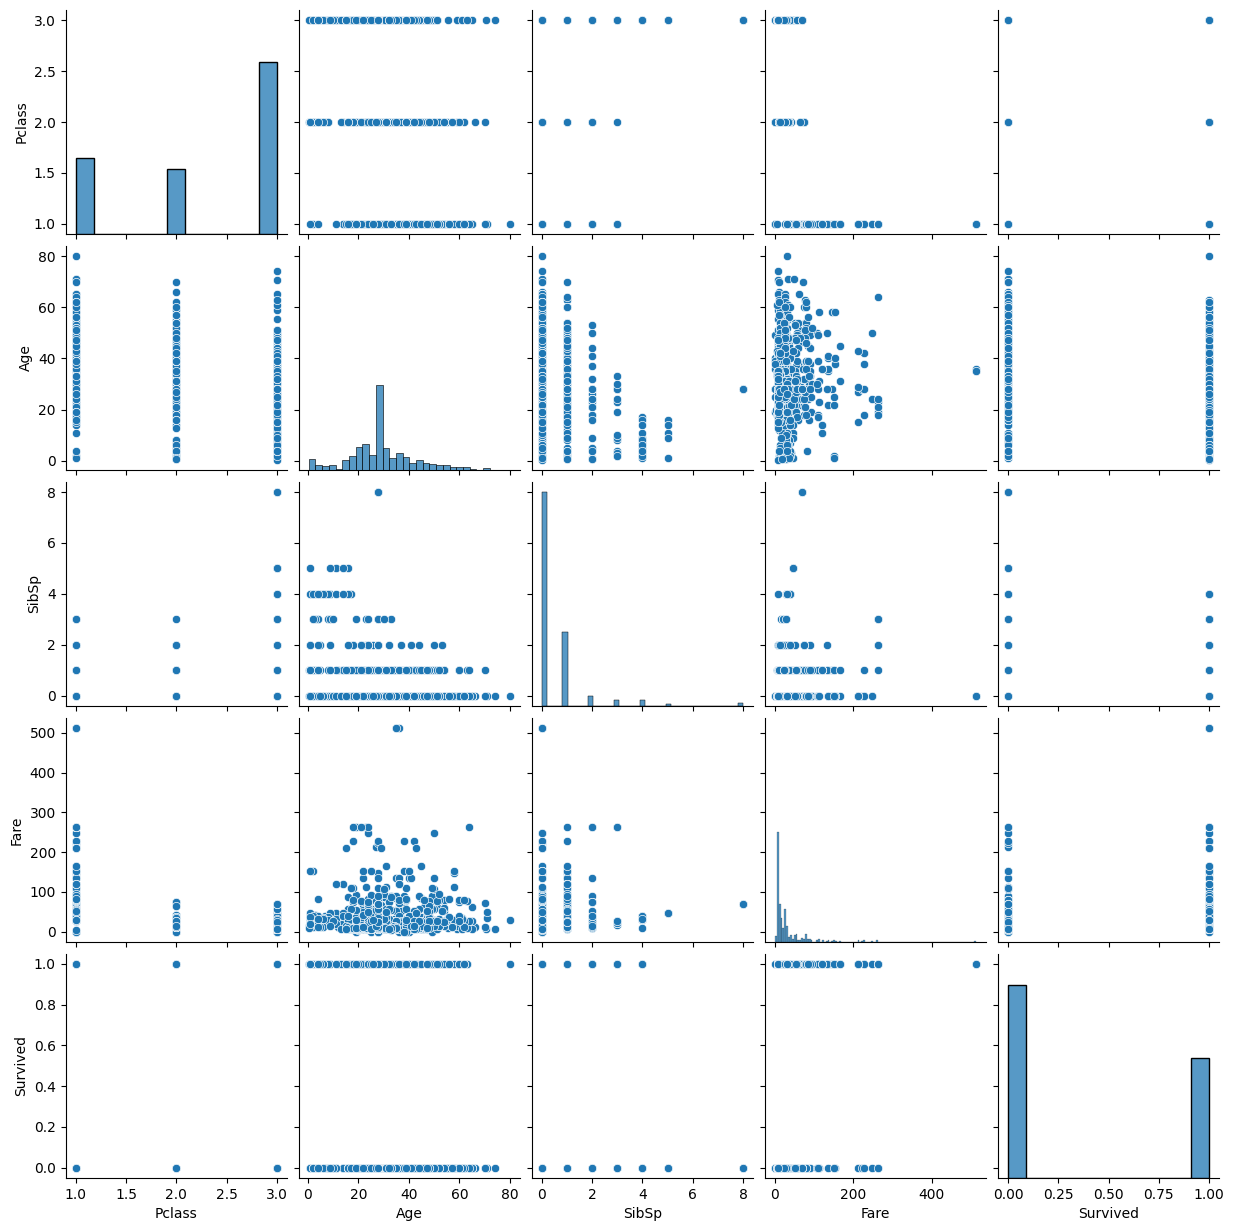

In [10]:
# Matrix plot
import seaborn as sns

sns.pairplot(data=t[['Pclass', 'Sex', 'Age', 'SibSp', 'Fare', 'Survived']])

In [11]:
# Prepare Data
X = t[['Pclass', 'Sex', 'Age', 'SibSp', 'Fare']]  # input data

y = t['Survived']  # output

In [12]:
# import algorithm

from sklearn.linear_model import LinearRegression

In [13]:
model = LinearRegression()
model

LinearRegression()

In [18]:
# Convert categorical data into numerical data
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
X['Sex'] = le.fit_transform(X['Sex'])

# Train the model
model.fit(X, y)

/tmp/ipykernel_1341/3719686340.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X['Sex'] = le.fit_transform(X['Sex'])


LinearRegression()

In [31]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import LabelEncoder
import gradio as gr

# 1. Load the dataset
url = 'https://raw.githubusercontent.com/datasciencedojo/datasets/refs/heads/master/titanic.csv'
df = pd.read_csv(url)

# 2. Preprocess missing values
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Fare'] = df['Fare'].fillna(df['Fare'].median())

# 3. Features and Target selection
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Fare']
target = 'Survived'

X_raw = df[features].copy()
y_raw = df[target]

# Encode categorical variables
label_encoder = LabelEncoder()
X_raw['Sex'] = label_encoder.fit_transform(X_raw['Sex'])

# 4. Train/Test Split & Model Training
X_tr, X_te, y_tr, y_te = train_test_split(X_raw, y_raw, test_size=0.2, random_state=42)

rf_model = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
rf_model.fit(X_tr, y_tr)

# 5. Evaluate accuracy
train_acc = accuracy_score(y_tr, rf_model.predict(X_tr))
test_acc = accuracy_score(y_te, rf_model.predict(X_te))
print(f"Model Trained Successfully!")
print(f"Training Accuracy: {train_acc*100:.2f}%")
print(f"Testing Accuracy: {test_acc*100:.2f}%")

# 6. Predict function for Gradio
def predict_survival(pclass, sex, age, sibsp, fare):
    # Transform sex back using same logic (female -> 0, male -> 1)
    sex_encoded = label_encoder.transform([sex])[0]

    # Make prediction
    input_data = pd.DataFrame([[pclass, sex_encoded, age, sibsp, fare]], columns=features)
    prob = rf_model.predict_proba(input_data)[0]
    prediction = rf_model.predict(input_data)[0]

    prob_survival = prob[1] * 100
    prob_death = prob[0] * 100

    status = "🟢 Survived" if prediction == 1 else "🔴 Perished"

    output_html = f"""
    <div style='text-align: center; padding: 15px; border-radius: 10px; background-color: #f8f9fa;'>
        <h2 style='color: {'#28a745' if prediction == 1 else '#dc3545'}'>{status}</h2>
        <p style='font-size: 1.1em;'>Chance of Survival: <strong>{prob_survival:.2f}%</strong></p>
        <p style='font-size: 1.1em;'>Chance of Perishing: <strong>{prob_death:.2f}%</strong></p>
    </div>
    """
    return output_html

# 7. Build the Gradio Interface
with gr.Blocks(theme=gr.themes.Soft()) as demo:
    gr.Markdown("""
    # 🚢 Titanic Survival Predictor
    Enter passenger details below to predict their likelihood of survival based on the machine learning model.
    """)

    with gr.Row():
        with gr.Column():
            pclass = gr.Dropdown(choices=[1, 2, 3], value=3, label="Passenger Class (1st = Upper, 2nd = Middle, 3rd = Lower)")
            sex = gr.Radio(choices=list(label_encoder.classes_), value="male", label="Sex")
            age = gr.Slider(minimum=0, maximum=100, value=28, step=1, label="Age")
            sibsp = gr.Slider(minimum=0, maximum=8, value=0, step=1, label="Siblings / Spouses Aboard")
            fare = gr.Number(value=32.0, label="Fare Paid (British Pounds)")
            predict_btn = gr.Button("🔮 Predict Survival", variant="primary")

        with gr.Column():
            output_box = gr.HTML(label="Prediction Result")

    predict_btn.click(
        fn=predict_survival,
        inputs=[pclass, sex, age, sibsp, fare],
        outputs=output_box
    )

demo.launch(quiet=True)

Model Trained Successfully!
Training Accuracy: 87.78%
Testing Accuracy: 81.01%


/tmp/ipykernel_1341/1744352944.py:66: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


* Running on public URL: https://178cf07887a4b8eb92.gradio.live


In [19]:
# select first 5 records for testing
#test_data = X.sample(5)
test_data = X.head(5)
test_data

,Pclass,Sex,Age,SibSp,Fare
0,3,1,22.0,1,7.2500
1,1,0,38.0,1,71.2833
2,3,0,26.0,0,7.9250
3,1,0,35.0,1,53.1000
4,3,1,35.0,0,8.0500


In [20]:
y.head().values

array([0, 1, 1, 1, 0])

In [21]:
# now use above test data for prediction
model.predict(test_data) # PREDICTED

array([0.09661871, 0.87860169, 0.62878836, 0.8894659 , 0.07027106])

In [22]:
X[:2]   # input

,Pclass,Sex,Age,SibSp,Fare
0,3,1,22.0,1,7.2500
1,1,0,38.0,1,71.2833


In [23]:
y[:2] # output

,Survived
0,0
1,1


In [24]:
# lets split the data
from sklearn.model_selection import train_test_split

In [25]:
X_train,X_test,y_train,y_test = train_test_split(X,y,train_size=.8)  # 80|20

In [26]:
X_test

,Pclass,Sex,Age,SibSp,Fare
493,1,1,71.0,0,49.5042
413,2,1,28.0,0,0.0000
431,3,0,28.0,1,16.1000
20,2,1,35.0,0,26.0000
87,3,1,28.0,0,8.0500
...,...,...,...,...,...
27,1,1,19.0,3,263.0000
798,3,1,30.0,0,7.2292
36,3,1,28.0,0,7.2292
271,3,1,25.0,0,0.0000


In [27]:
# testing---> X_test (unseen data  - a data which we have not passed through training)
y_pred = model.predict(X_test)
y_pred  # Predicted result

array([ 2.22279489e-01,  2.80240160e-01,  5.71823576e-01,  2.49078125e-01,
        1.10632053e-01,  6.17194728e-01,  7.02710627e-02,  9.32902601e-02,
        1.62563072e-01,  1.53841182e-01,  4.49333798e-01,  6.17194728e-01,
        5.48547869e-01,  1.30812548e-01,  1.01320276e+00,  5.03942230e-01,
        9.88172968e-02,  1.11145072e-01,  5.63140003e-01,  8.75140732e-02,
        2.66657556e-01,  5.65952145e-01,  5.61332918e-01,  2.85016541e-01,
        7.68066677e-01,  5.71611292e-01,  5.33196111e-01,  1.26125051e-02,
        1.10597263e-01,  3.85260078e-01,  7.97748733e-04,  3.02137205e-01,
        6.48526038e-02,  9.69198403e-01,  1.10525911e-01,  1.10553933e-01,
        1.10632053e-01,  7.26782550e-01,  3.63903457e-01,  1.10340163e-01,
        1.68200673e-01,  2.35781270e-02,  8.47456157e-01,  2.35956657e-01,
        1.10341649e-01,  1.03421849e+00,  4.63487488e-01,  6.39515208e-01,
        1.11154836e-01,  1.73729196e-01,  1.10632053e-01,  2.50244503e-01,
        2.52456479e-01,  

In [28]:
y_test.values  # actual result

array([0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0,
       1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0,
       0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0,
       1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0,
       1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0,
       1, 1, 0])

In [29]:
model.score(X_train,y_train)

0.4035585243478522

In [30]:
model.score(X_test,y_test)

0.35529035420598376